In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import numpy as np
import os

path = r'/mnt/nfs_fineprint/tmp/PYSUT/pySUTO/data/proc/datafeed/baci/baci_copper_root.csv'

baci = pd.read_csv(path)
baci

,Year,Sector,Region_from,Region_to,Copper_flow,Region_from_name,Region_to_name
0,1995,Anode,12,251,0.078337,Algeria,France
1,1995,Anode,31,792,0.034285,Azerbaijan,TÃ¼rkiye
2,1995,Anode,36,156,0.000237,Australia,China
3,1995,Anode,36,344,0.003028,Australia,"China, Hong Kong SAR"
4,1995,Anode,36,360,0.000122,Australia,Indonesia
...,...,...,...,...,...,...,...
405242,2024,Scrap,842,724,0.635253,USA,Spain
405243,2024,Scrap,842,792,0.056408,USA,TÃ¼rkiye
405244,2024,Scrap,860,792,0.010967,Uzbekistan,TÃ¼rkiye
405245,2024,Scrap,894,508,0.000432,Zambia,Mozambique


In [20]:
def compute_trade_balance(df):
    """
    Compute physical trade balance (exports - imports) for each
    Year, Sector, Region.

    Parameters
    ----------
    df : pandas.DataFrame
        BACI copper trade table with columns:
        Year, Sector, Region_from, Region_to, Copper_flow,
        Region_from_name, Region_to_name

    Returns
    -------
    pandas.DataFrame
        Columns:
        Year, Sector, Region, Region_name, Trade_balance,
        Exports, Imports
    """

    # ----- Exports -----
    exp = df[['Year','Sector','Region_from','Region_from_name','Copper_flow']].copy()
    exp = exp.rename(columns={
        'Region_from':'Region',
        'Region_from_name':'Region_name'
    })
    exp['Exports'] = exp['Copper_flow']
    exp['Imports'] = 0

    # ----- Imports -----
    imp = df[['Year','Sector','Region_to','Region_to_name','Copper_flow']].copy()
    imp = imp.rename(columns={
        'Region_to':'Region',
        'Region_to_name':'Region_name'
    })
    imp['Exports'] = 0
    imp['Imports'] = imp['Copper_flow']

    # ----- Stack -----
    trade = pd.concat([exp, imp], ignore_index=True)

    # ----- Aggregate -----
    trade = (
        trade
        .groupby(['Year','Sector','Region','Region_name'], as_index=False)
        [['Exports','Imports']]
        .sum()
    )

    # ----- Balance -----
    trade['Trade_balance'] = trade['Imports'] - trade['Exports']

    # nicer column order
    trade = trade[['Year','Sector','Region','Region_name','Exports','Imports','Trade_balance']]

    return trade

In [21]:
ptb = compute_trade_balance(baci)
ptb

,Year,Sector,Region,Region_name,Exports,Imports,Trade_balance
0,1995,Anode,12,Algeria,0.078337,0.060078,-0.018259
1,1995,Anode,31,Azerbaijan,0.034285,0.000000,-0.034285
2,1995,Anode,32,Argentina,0.000000,0.015514,0.015514
3,1995,Anode,36,Australia,0.045958,0.458277,0.412319
4,1995,Anode,40,Austria,0.061111,0.219273,0.158163
...,...,...,...,...,...,...,...
30838,2024,Scrap,834,United Rep. of Tanzania,0.018826,0.000000,-0.018826
30839,2024,Scrap,842,USA,2.991930,0.082486,-2.909443
30840,2024,Scrap,860,Uzbekistan,0.010967,0.000000,-0.010967
30841,2024,Scrap,887,Yemen,0.000000,0.002000,0.002000


In [22]:
def plot_trade_balance_country(df, country, sectors=None):
    """
    Plot physical trade balance by sector for a selected country.

    Parameters
    ----------
    df : pandas.DataFrame
        Output of compute_trade_balance() with columns:
        Year, Sector, Region, Region_name, Exports, Imports, Trade_balance

    country : str
        Country name (Region_name)

    sectors : list[str], optional
        Optional list of sectors to include
    """

    # filter country
    data = df[df["Region_name"] == country].copy()

    if sectors is not None:
        data = data[data["Sector"].isin(sectors)]

    if data.empty:
        raise ValueError(f"No data found for country: {country}")

    # modern style
    sns.set_style("whitegrid")

    # consistent sector colors
    sectors_unique = sorted(data["Sector"].unique())
    palette = sns.color_palette("Set2", len(sectors_unique))
    sector_colors = dict(zip(sectors_unique, palette))

    fig, ax = plt.subplots(figsize=(10,5))

    for sector in sectors_unique:
        d = data[data["Sector"] == sector]

        ax.plot(
            d["Year"],
            d["Trade_balance"],
            label=sector,
            color=sector_colors[sector],
            linewidth=2
        )

    # zero line
    ax.axhline(0, color="black", linewidth=1.2, linestyle="--", alpha=0.6)

    # labels
    ax.set_ylabel("Physical trade balance (kt Cu)")
    ax.set_xlabel("Year")

    # remove top/right spines
    sns.despine()

    # legend outside
    ax.legend(
        title="Sector",
        frameon=False,
        bbox_to_anchor=(1.02,1),
        loc="upper left"
    )

    plt.tight_layout()
    plt.show()

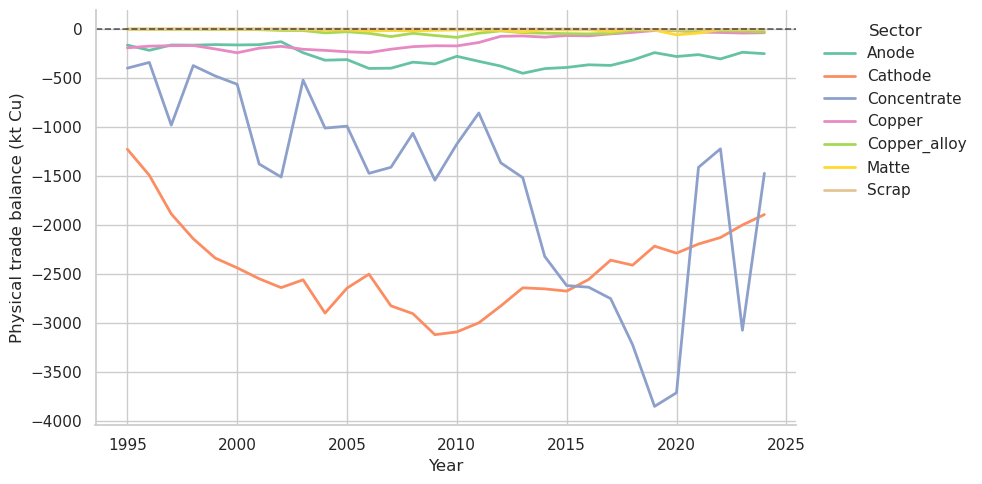

In [23]:
plot_trade_balance_country(ptb, "Chile")

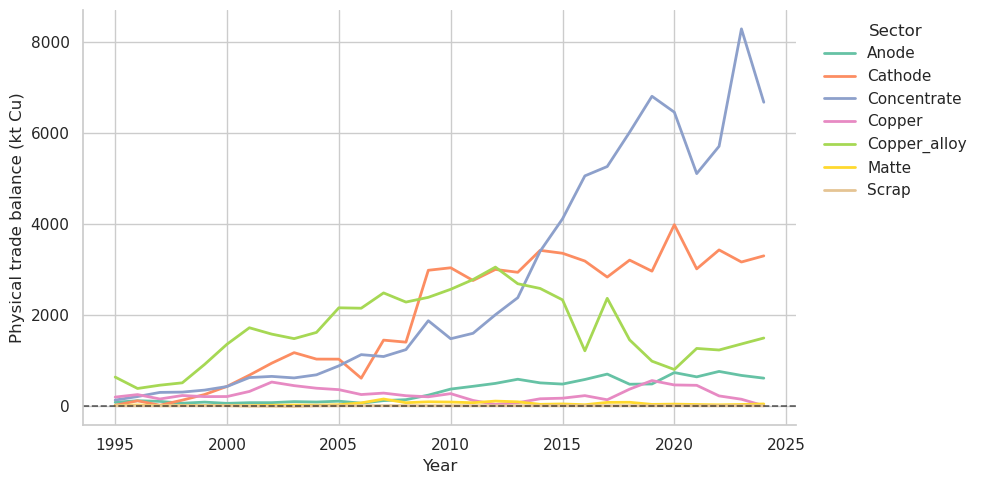

In [24]:
plot_trade_balance_country(ptb, "China")

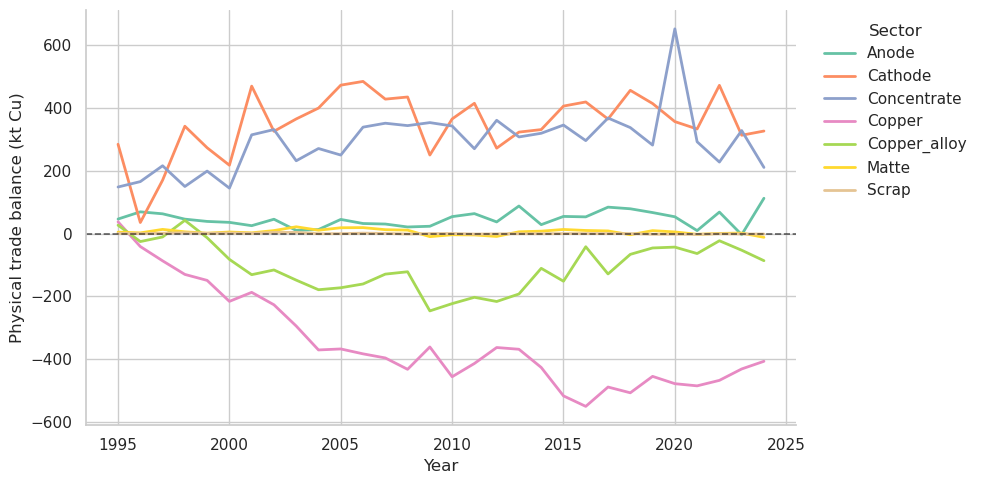

In [25]:
plot_trade_balance_country(ptb, "Germany")

In [58]:
def plot_trade_balance_facets(df, top_n=6, country=None, colors=None):
    """
    Faceted stacked trade balance by country OR selected countries.

    Parameters
    ----------
    df : DataFrame
        Columns: Year, Sector, Region_name, Trade_balance

    top_n : int
        Number of countries (used if country=None)

    country : str or list, optional
        Country or list of countries to plot

    colors : dict, optional
        Mapping {sector: color}
    """

    import pandas as pd
    import seaborn as sns
    import matplotlib.pyplot as plt

    # -------------------------
    # Country selection + validation
    # -------------------------
    if country is not None:
        if isinstance(country, str):
            country = [country]

        available = set(df["Region_name"].unique())
        requested = set(country)

        missing = requested - available
        if missing:
            raise ValueError(
                f"❌ Countries not found in dataset: {sorted(missing)}"
            )

        df_plot = df[df["Region_name"].isin(country)].copy()

    else:
        top_countries = (
            df.groupby("Region_name")["Trade_balance"]
            .sum()
            .abs()
            .sort_values(ascending=False)
            .head(top_n)
            .index
        )

        df_plot = df[df["Region_name"].isin(top_countries)].copy()

    # -------------------------
    # Sector setup
    # -------------------------
    sectors = sorted(df_plot["Sector"].unique())

    if colors is not None:
        sector_colors = colors

        missing_colors = set(sectors) - set(sector_colors.keys())
        if missing_colors:
            raise ValueError(
                f"❌ Missing colors for sectors: {missing_colors}"
            )
    else:
        palette = sns.color_palette("viridis", len(sectors))
        sector_colors = dict(zip(sectors, palette))

    sns.set_theme(style="whitegrid")

    # -------------------------
    # Adaptive facet layout
    # -------------------------
    n_countries = df_plot["Region_name"].nunique()
    col_wrap = min(3, n_countries)

    g = sns.FacetGrid(
        df_plot,
        col="Region_name",
        col_wrap=col_wrap,
        height=3.8,
        sharey=False
    )

    # -------------------------
    # Plot function (FIXED SCOPE)
    # -------------------------
    def stacked_bar(data, sectors, sector_colors, **kwargs):

        ax = plt.gca()

        pivot = (
            data.pivot_table(
                index="Year",
                columns="Sector",
                values="Trade_balance",
                aggfunc="sum"
            )
            .fillna(0)
        )

        years = pivot.index
        pos_stack = pd.Series(0, index=years)
        neg_stack = pd.Series(0, index=years)

        for sector in sectors:
            vals = pivot[sector] if sector in pivot else 0

            pos = vals.clip(lower=0)
            neg = vals.clip(upper=0)

            ax.bar(
                years, pos,
                bottom=pos_stack,
                color=sector_colors[sector],
                width=0.8,
                edgecolor='none'
            )

            ax.bar(
                years, neg,
                bottom=neg_stack,
                color=sector_colors[sector],
                width=0.8,
                edgecolor='none'
            )

            pos_stack += pos
            neg_stack += neg

        ax.axhline(0, color="black", lw=1)

    g.map_dataframe(
        stacked_bar,
        sectors=sectors,
        sector_colors=sector_colors
    )

    # -------------------------
    # Titles (clean)
    # -------------------------
    g.set_titles("{col_name}", size=12, weight="bold")

    # -------------------------
    # Labels
    # -------------------------
    g.set_axis_labels("Year", "PTB [I-E] (kt Cu)")

    # -------------------------
    # Legend
    # -------------------------
    handles = [
        plt.Line2D([0], [0], color=sector_colors[s], lw=6)
        for s in sectors
    ]

    g.fig.legend(
        handles,
        sectors,
        title="Sector",
        loc="lower center",
        ncol=len(sectors),
        frameon=False
    )

    sns.despine()

    # -------------------------
    # Layout fix (prevents cut-off)
    # -------------------------
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.12)

    plt.show()

In [34]:
ptb

,Year,Sector,Region,Region_name,Exports,Imports,Trade_balance
0,1995,Anode,12,Algeria,0.078337,0.060078,-0.018259
1,1995,Anode,31,Azerbaijan,0.034285,0.000000,-0.034285
2,1995,Anode,32,Argentina,0.000000,0.015514,0.015514
3,1995,Anode,36,Australia,0.045958,0.458277,0.412319
4,1995,Anode,40,Austria,0.061111,0.219273,0.158163
...,...,...,...,...,...,...,...
30838,2024,Scrap,834,United Rep. of Tanzania,0.018826,0.000000,-0.018826
30839,2024,Scrap,842,USA,2.991930,0.082486,-2.909443
30840,2024,Scrap,860,Uzbekistan,0.010967,0.000000,-0.010967
30841,2024,Scrap,887,Yemen,0.000000,0.002000,0.002000


In [49]:
ptb.Sector.unique()

array(['Anode', 'Cathode', 'Concentrate', 'Copper', 'Copper_alloy',
       'Matte', 'Scrap'], dtype=object)

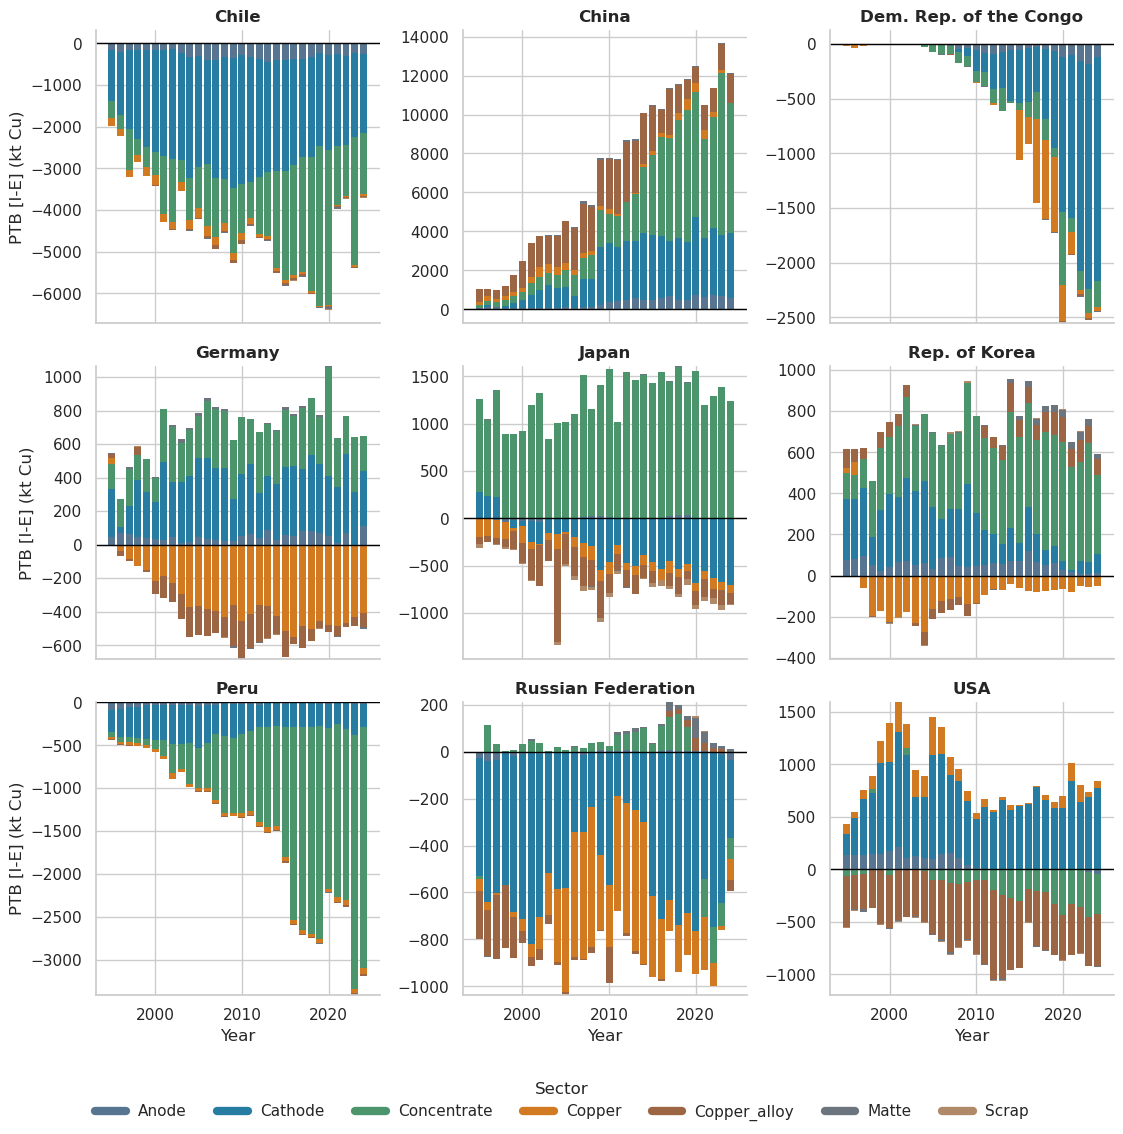

In [59]:
countries = ["Chile", "China", "Peru",
             "Russian Federation", "USA", "Germany",
             "Japan", "Rep. of Korea", 'Dem. Rep. of the Congo']

sector_colors = {
    'Copper':        '#D17A22',  # copper orange (anchor color)
    'Copper_alloy':  '#9C6644',  # darker brownish copper

    'Concentrate':   '#4C956C',  # mineral green
    'Matte':         '#6C757D',  # industrial gray

    'Anode':         '#577590',  # muted blue
    'Cathode':       '#277DA1',  # brighter refined blue

    'Scrap':         '#B08968',  # recycled / earthy tone
}

plot_trade_balance_facets(ptb, country=countries, colors=sector_colors)